# 03 · Modelado: clasificación y regresión

1. Línea base (modelos "tontos").
2. **Clasificadores:** GaussianNB, Decision Tree, Random Forest, SVM, con `GridSearchCV` pequeño y validación cruzada agrupada por paciente.
3. **Regresores** sobre el target ordinal: Decision Tree, Random Forest y SVR.
4. Guardar modelos y tablas en `artifacts/` (los usa el notebook 04).

Los modelos son `Pipeline`s de `src/models.py` (escalado → top 20 → modelo), así que **todo se ajusta solo con train**. SVM y SVR son lentos, por eso se entrenan con una **submuestra de ~20,000 filas** de train (agrupada por paciente).

In [1]:
import os
import sys

# Los notebooks viven en notebooks/; subimos a la raíz del proyecto para que funcionen las rutas
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import warnings

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"  # también en los procesos de joblib

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, precision_score, recall_score

from src import evaluation as ev
from src.data import clean_data, group_subsample, load_data, split_train_test
from src.features import add_features
from src.models import SEED, cross_validate_models, get_models, get_regressors, tune_model

ART = Path("artifacts")
(ART / "models").mkdir(parents=True, exist_ok=True)
%matplotlib inline

## 1. Datos y split (igual que el notebook 02)

In [2]:
df = clean_data(load_data())
X, y, y_reg, groups = add_features(df), df["target"], df["target_reg"], df["patient_nbr"]
tr, te = split_train_test(y, groups, seed=SEED)
X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
yr_train, yr_test, g_train = y_reg.iloc[tr], y_reg.iloc[te], groups.iloc[tr]

sub = group_subsample(y_train, g_train, 20_000, seed=SEED)
X_sub, y_sub, yr_sub, g_sub = (
    X_train.iloc[sub],
    y_train.iloc[sub],
    yr_train.iloc[sub],
    g_train.iloc[sub],
)
print(
    f"train: {len(X_train):,} · test: {len(X_test):,} · submuestra: {len(X_sub):,} ({y_sub.mean():.1%} positivos)"
)

train: 79,473 · test: 19,870 · submuestra: 19,867 (11.4% positivos)


## 2. Línea base

Con ~11 % de positivos, la accuracy engaña. Dos modelos "tontos" fijan el piso: "nadie reingresa" y "todos reingresan".

In [3]:
filas = []
for nombre, k in [("Nadie reingresa", 0), ("Todos reingresan", 1)]:
    pred = DummyClassifier(strategy="constant", constant=k).fit(X_train, y_train).predict(X_test)
    filas.append(
        {
            "modelo tonto": nombre,
            "accuracy": (pred == y_test).mean(),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred, zero_division=0),
        }
    )
base = pd.DataFrame(filas).round(3)
base

,modelo tonto,accuracy,precision,recall,F1
0,Nadie reingresa,0.886,0.000,0.0,0.000
1,Todos reingresan,0.114,0.114,1.0,0.204


"Nadie reingresa" tiene accuracy altísima y **F1 = 0**. "Todos reingresan" marca el **piso de F1** que un modelo útil debe superar.

### Por qué GaussianNB y SVM

El target es `readmitted == "<30"` (sí/no), así que el problema es **binario** y ambos modelos aplican directamente.

- **Gaussian Naive Bayes:** línea base probabilística, muy rápida. Supone variables independientes y gaussianas dentro de cada clase; aquí casi todo es one-hot (binario), así que el supuesto se viola y se espera un rendimiento modesto. Sirve para saber cuánto aporta un modelo más flexible. No admite `class_weight`.
- **SVM (kernel RBF):** frontera no lineal, con `class_weight="balanced"` para el desbalance. Necesita variables escaladas (el `Pipeline` ya las escala). Entrenar escala entre O(n²) y O(n³), por eso se ajusta con la submuestra de ~20,000 filas. Se usa `decision_function` (un puntaje, no una probabilidad calibrada); eso no altera la curva ROC ni la PR.

### Sobre las métricas
El problema está **desbalanceado** (~11 % de positivos), por eso la accuracy engaña y ROC-AUC resulta optimista: los muchos verdaderos negativos mantienen baja la tasa de falsos positivos. **PR-AUC** mide solo lo que importa, qué tan bien se *priorizan* los reingresos reales (precisión vs. recall), y su línea base es la tasa de positivos (≈ 0.11), no 0.5. Recall, precision y F1 dependen del umbral.

La **selección** se hace con F1 de la clase `<30` (desempate por recall); ROC-AUC y PR-AUC se usan como apoyo en el notebook 04.

## 3. Clasificadores

| Modelo | Configuración inicial |
|---|---|
| **GaussianNB** | Sin parámetros (no soporta `class_weight`) |
| **DecisionTree** | `class_weight="balanced"` |
| **RandomForest** | `class_weight="balanced"` |
| **SVM** | Kernel RBF, `class_weight="balanced"` |

### 3.1 Búsqueda de hiperparámetros (`GridSearchCV`, 3 folds agrupados, métrica F1)
Cuadrículas pequeñas definidas en `PARAM_GRIDS` (profundidad, nº de árboles, `C`).

Qué controla cada hiperparámetro:

| Hiperparámetro | Modelo | Efecto |
|---|---|---|
| `max_depth`, `min_samples_leaf` | Decision Tree, Random Forest | Profundidad y tamaño mínimo de hoja: valores pequeños dan un modelo más simple (menos sobreajuste). |
| `n_estimators` | Random Forest | Número de árboles: más árboles estabilizan, con rendimientos decrecientes. |
| `C` | SVM, SVR | Penalización por error: pequeño = margen amplio (más regularizado); grande = ajusta más al train. |


In [4]:
models = {
    n: (tune_model(n, m, X_sub, y_sub, g_sub) if n != "GaussianNB" else m)
    for n, m in get_models().items()
}

  RandomForest: {'clf__min_samples_leaf': 20, 'clf__n_estimators': 200} (f1 = 0.271)


  DecisionTree: {'clf__max_depth': 3, 'clf__min_samples_leaf': 20} (f1 = 0.267)


  SVM: {'clf__C': 0.5} (f1 = 0.263)


  MLP: {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (32, 16)} (f1 = 0.221)


### 3.2 Validación cruzada (5 folds, agrupados por paciente)

Cada modelo recibe 5 valores de F1 en lugar de uno. El escalado y la selección de columnas se reajustan dentro de cada fold.

In [5]:
cv_results = cross_validate_models(models, X_sub, y_sub, g_sub)
cv_results.to_csv(ART / "cv_results.csv", index=False)
resumen_cv = (
    cv_results.groupby("model")["f1"]
    .agg(["mean", "std", "min", "max"])
    .sort_values("mean", ascending=False)
    .round(3)
)
resumen_cv

  GaussianNB: F1 medio = 0.213 (±0.029)


  RandomForest: F1 medio = 0.273 (±0.007)


  DecisionTree: F1 medio = 0.266 (±0.009)


  SVM: F1 medio = 0.260 (±0.011)


  MLP: F1 medio = 0.228 (±0.009)


,mean,std,min,max
model,,,,
RandomForest,0.273,0.008,0.262,0.284
DecisionTree,0.266,0.010,0.250,0.277
SVM,0.260,0.013,0.239,0.271
MLP,0.228,0.010,0.215,0.240
GaussianNB,0.213,0.032,0.178,0.255


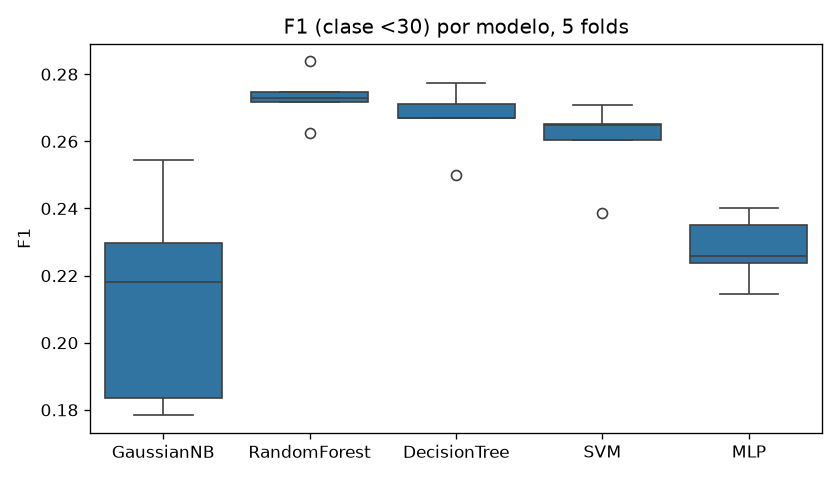

In [6]:
ev.plot_cv_boxplot(cv_results)
display(Image(filename="reports/figures/cv_boxplot.png"))

Los modelos quedan en un rango estrecho de F1; las cajas se solapan, así que las diferencias son pequeñas.

### 3.3 Evaluación en test

Se entrena cada modelo con la submuestra y se mide en **test** (pacientes que ninguno vio).

In [7]:
for model in models.values():
    model.fit(X_sub, y_sub)
metrics = ev.compute_metrics(models, X_test, y_test)
metrics.to_csv(ART / "metrics.csv", index=False)
for name, model in models.items():
    joblib.dump(model, ART / "models" / f"{name}.joblib")
metrics.set_index("model")

,accuracy,precision,recall,f1,auc
model,,,,,
GaussianNB,0.8378,0.2336,0.1860,0.2071,0.6377
RandomForest,0.6844,0.1802,0.4989,0.2647,0.6508
DecisionTree,0.6540,0.1666,0.5095,0.2511,0.6357
SVM,0.6544,0.1740,0.5431,0.2636,0.6420
MLP,0.6348,0.1573,0.5064,0.2400,0.6082


## 5. Regresión

Target ordinal (ADR-02): `NO`=0, `>30`=1, `<30`=2. Mismos datos, mismo split y misma submuestra. Métricas: MSE, MAE y RMSE.

In [9]:
regressors = {
    n: tune_model(n, m, X_sub, yr_sub, g_sub, regression=True) for n, m in get_regressors().items()
}
reg_metrics = ev.compute_regression_metrics(regressors, X_test, yr_test)
reg_metrics.to_csv(ART / "metrics_regression.csv", index=False)
for name, model in regressors.items():
    joblib.dump(model, ART / "models" / f"{name}.joblib")
reg_metrics.set_index("model")

  DecisionTreeRegressor: {'clf__max_depth': 3, 'clf__min_samples_leaf': 20} (neg_root_mean_squared_error = -0.658)


  RandomForestRegressor: {'clf__min_samples_leaf': 40, 'clf__n_estimators': 200} (neg_root_mean_squared_error = -0.653)


  SVR: {'clf__C': 0.5} (neg_root_mean_squared_error = -0.693)


,mse,mae,rmse
model,,,
DecisionTreeRegressor,0.4396,0.5729,0.6631
RandomForestRegressor,0.4327,0.5625,0.6578
SVR,0.4896,0.5212,0.6997


In [10]:
# Referencia: un regresor "tonto" que siempre predice la media del train
media = yr_train.mean()
rmse_base = float(np.sqrt(((yr_test - media) ** 2).mean()))
mae_base = float((yr_test - media).abs().mean())
print(f"Predecir siempre la media ({media:.2f}): RMSE = {rmse_base:.3f} · MAE = {mae_base:.3f}")

Predecir siempre la media (0.59): RMSE = 0.686 · MAE = 0.619


## 6. Resumen

Los modelos y tablas quedaron en `artifacts/`. En el notebook **04** se comparan con gráficas y se elige el ganador (criterio ADR-03).

> Nota: `train.py` ejecuta exactamente este mismo flujo desde la terminal y además reentrena el ganador con todo el train.

> Un rendimiento modesto es normal en este dataset: con la información disponible al alta solo se explica una parte del reingreso, y las diferencias entre modelos suelen ser menores que la variación entre folds.
